# Dimensionless Banked Curve Analysis

## Frictionless Banked Curve: Dimensionless Formulation

This notebook explores the dimensionless analysis of a car turning on a frictionless banked curve.

**Key Result**: The safe turning speed is entirely determined by the banking angle $\phi$:

$$v^* = \sqrt{\tan\phi}$$

where $v^* = \frac{v}{\sqrt{rg}}$ is the dimensionless speed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

## Part 1: Characteristic Scales

For a banked curve, the characteristic scales are:

- **Velocity scale**: $v_{\text{char}} = \sqrt{rg}$
- **Time scale**: $t_{\text{char}} = \sqrt{r/g}$
- **Angular frequency scale**: $\omega_{\text{char}} = \sqrt{g/r}$

In [2]:
def velocity_scale(r, g):
    return np.sqrt(r * g)

def time_scale(r, g):
    return np.sqrt(r / g)

def angular_freq_scale(r, g):
    return np.sqrt(g / r)

r_earth = 50
g_earth = 10
r_moon = 50
g_moon = 1.6

v_char_earth = velocity_scale(r_earth, g_earth)
t_char_earth = time_scale(r_earth, g_earth)
omega_char_earth = angular_freq_scale(r_earth, g_earth)

v_char_moon = velocity_scale(r_moon, g_moon)
t_char_moon = time_scale(r_moon, g_moon)
omega_char_moon = angular_freq_scale(r_moon, g_moon)

print(f'Earth (r={r_earth}m, g={g_earth}m/s²):')
print(f'  v_char = {v_char_earth:.2f} m/s')
print(f'  t_char = {t_char_earth:.2f} s')
print(f'  omega_char = {omega_char_earth:.4f} rad/s')
print()
print(f'Moon (r={r_moon}m, g={g_moon}m/s²):')
print(f'  v_char = {v_char_moon:.2f} m/s')
print(f'  t_char = {t_char_moon:.2f} s')
print(f'  omega_char = {omega_char_moon:.4f} rad/s')

Earth (r=50m, g=10m/s²):
  v_char = 22.36 m/s
  t_char = 2.24 s
  omega_char = 0.4472 rad/s

Moon (r=50m, g=1.6m/s²):
  v_char = 8.94 m/s
  t_char = 5.59 s
  omega_char = 0.1789 rad/s


## Part 2: Dimensionless Speed vs Banking Angle

The key result from dimensional analysis:

$$v^* = \sqrt{\tan\phi}$$

This depends **only** on the banking angle $\phi$, not on mass, radius, or gravity!

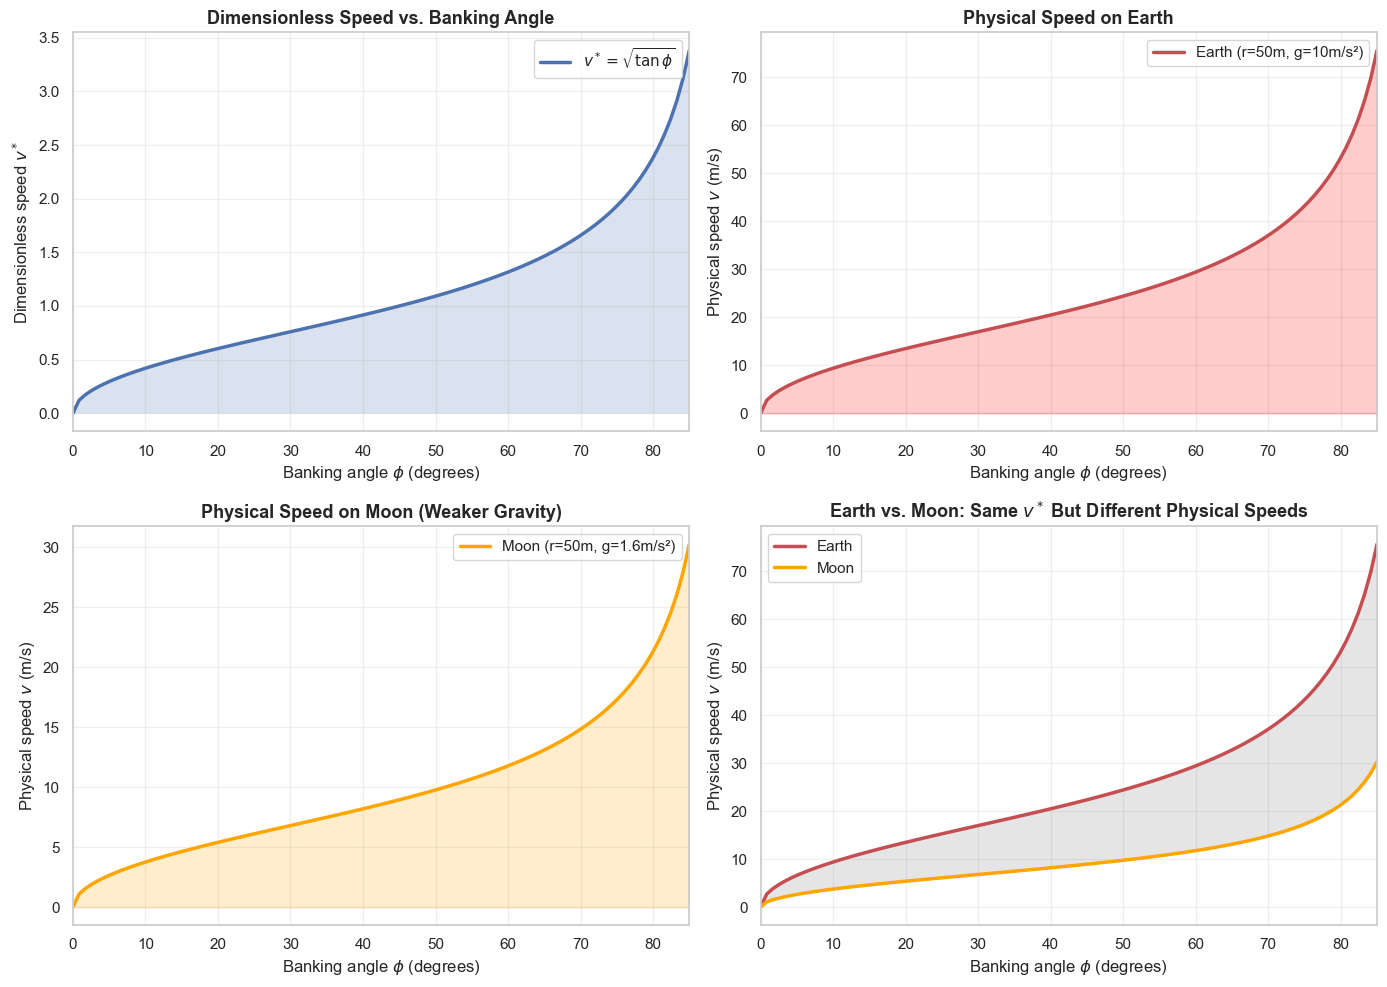


Key Insight: The dimensionless speed v* is IDENTICAL on Earth and Moon!
Physical speeds differ due to different gravity: v = v* × sqrt(rg)


In [3]:
def dimensionless_speed(phi):
    return np.sqrt(np.tan(phi))

def physical_speed(phi, r, g):
    v_star = dimensionless_speed(phi)
    v_char = velocity_scale(r, g)
    return v_star * v_char

phi_deg = np.linspace(0, 85, 100)
phi_rad = np.radians(phi_deg)
v_star = dimensionless_speed(phi_rad)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.plot(phi_deg, v_star, 'b-', linewidth=2.5, label=r'$v^* = \sqrt{\tan\phi}$')
ax.fill_between(phi_deg, 0, v_star, alpha=0.2)
ax.set_xlabel(r'Banking angle $\phi$ (degrees)', fontsize=12)
ax.set_ylabel(r'Dimensionless speed $v^*$', fontsize=12)
ax.set_title('Dimensionless Speed vs. Banking Angle', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
ax.set_xlim([0, 85])

ax = axes[0, 1]
v_earth = physical_speed(phi_rad, r_earth, g_earth)
ax.plot(phi_deg, v_earth, 'r-', linewidth=2.5, label=f'Earth (r={r_earth}m, g={g_earth}m/s²)')
ax.fill_between(phi_deg, 0, v_earth, alpha=0.2, color='red')
ax.set_xlabel(r'Banking angle $\phi$ (degrees)', fontsize=12)
ax.set_ylabel(r'Physical speed $v$ (m/s)', fontsize=12)
ax.set_title('Physical Speed on Earth', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
ax.set_xlim([0, 85])

ax = axes[1, 0]
v_moon = physical_speed(phi_rad, r_moon, g_moon)
ax.plot(phi_deg, v_moon, 'orange', linewidth=2.5, label=f'Moon (r={r_moon}m, g={g_moon}m/s²)')
ax.fill_between(phi_deg, 0, v_moon, alpha=0.2, color='orange')
ax.set_xlabel(r'Banking angle $\phi$ (degrees)', fontsize=12)
ax.set_ylabel(r'Physical speed $v$ (m/s)', fontsize=12)
ax.set_title('Physical Speed on Moon (Weaker Gravity)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
ax.set_xlim([0, 85])

ax = axes[1, 1]
ax.plot(phi_deg, v_earth, 'r-', linewidth=2.5, label='Earth')
ax.plot(phi_deg, v_moon, 'orange', linewidth=2.5, label='Moon')
ax.fill_between(phi_deg, v_moon, v_earth, alpha=0.2, color='gray')
ax.set_xlabel(r'Banking angle $\phi$ (degrees)', fontsize=12)
ax.set_ylabel(r'Physical speed $v$ (m/s)', fontsize=12)
ax.set_title('Earth vs. Moon: Same $v^*$ But Different Physical Speeds', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
ax.set_xlim([0, 85])

plt.tight_layout()
plt.show()

print('\nKey Insight: The dimensionless speed v* is IDENTICAL on Earth and Moon!')
print('Physical speeds differ due to different gravity: v = v* × sqrt(rg)')

## Part 3: Universal Scaling Behavior

The power of dimensionless analysis: all banked curves with the same angle behave identically in dimensionless form.

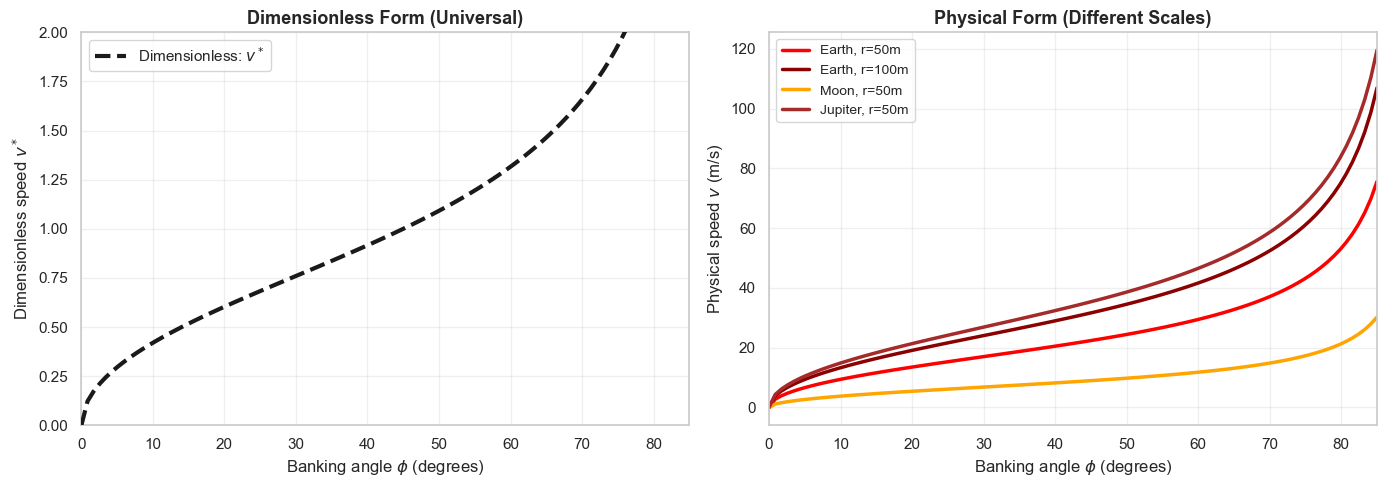

Universal Behavior Table:
Scenario                  phi=30°         phi=45°         phi=60°        
Scenario                          phi=30°         phi=45°         phi=60°
Dimensionless v*                   0.7598          1.0000          1.3161
----------------------------------------------------------------------
Earth, r=50m                 16.99 m/s    22.36 m/s    29.43 m/s
Earth, r=100m                24.03 m/s    31.62 m/s    41.62 m/s
Moon, r=50m                   6.80 m/s     8.94 m/s    11.77 m/s
Jupiter, r=50m               26.86 m/s    35.36 m/s    46.53 m/s
----------------------------------------------------------------------
Earth, r=50m                 17.01 m/s        22.22 m/s        29.49 m/s
Earth, r=100m                24.05 m/s        31.43 m/s        41.70 m/s
Moon, r=50m                   6.80 m/s         8.89 m/s        11.80 m/s
Jupiter, r=50m               26.89 m/s        35.14 m/s        46.63 m/s


In [4]:
scenarios = [
    {'name': 'Earth, r=50m', 'r': 50, 'g': 10, 'color': 'red'},
    {'name': 'Earth, r=100m', 'r': 100, 'g': 10, 'color': 'darkred'},
    {'name': 'Moon, r=50m', 'r': 50, 'g': 1.6, 'color': 'orange'},
    {'name': 'Jupiter, r=50m', 'r': 50, 'g': 25, 'color': 'brown'},
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(phi_deg, v_star, 'k--', linewidth=3, label='Dimensionless: $v^*$', zorder=10)
ax.set_xlabel(r'Banking angle $\phi$ (degrees)', fontsize=12)
ax.set_ylabel(r'Dimensionless speed $v^*$', fontsize=12)
ax.set_title('Dimensionless Form (Universal)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
ax.set_xlim([0, 85])
ax.set_ylim([0, 2])

ax = axes[1]
for scenario in scenarios:
    v_phys = physical_speed(phi_rad, scenario['r'], scenario['g'])
    ax.plot(phi_deg, v_phys, linewidth=2.5, label=scenario['name'], color=scenario['color'])

ax.set_xlabel(r'Banking angle $\phi$ (degrees)', fontsize=12)
ax.set_ylabel(r'Physical speed $v$ (m/s)', fontsize=12)
ax.set_title('Physical Form (Different Scales)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
ax.set_xlim([0, 85])

plt.tight_layout()
plt.show()

print('Universal Behavior Table:')
print(f'{"Scenario":<25} {"phi=30°":<15} {"phi=45°":<15} {"phi=60°":<15}')
print('=' * 70)
angles = (30, 45, 60)

print('{:<25} {:>15} {:>15} {:>15}'.format(
    'Scenario', 'phi=30°', 'phi=45°', 'phi=60°'
))
print('=' * 70)

dimensionless_values = [
    dimensionless_speed(np.radians(angle)) for angle in angles
]
print('{:<25} {:>15.4f} {:>15.4f} {:>15.4f}'.format(
    'Dimensionless v*', *dimensionless_values
))
print('-' * 70)

for scenario in scenarios:
    speeds = [
        physical_speed(np.radians(angle), scenario['r'], scenario['g'])
        for angle in angles
    ]
    print('{:<25} {:>8.2f} m/s {:>8.2f} m/s {:>8.2f} m/s'.format(
        scenario['name'], *speeds
    ))
print('-' * 70)

for scenario in scenarios:
    v_phys = physical_speed(phi_rad, scenario['r'], scenario['g'])
    phi30_idx = np.argmin(np.abs(phi_deg-30))
    phi45_idx = np.argmin(np.abs(phi_deg-45))
    phi60_idx = np.argmin(np.abs(phi_deg-60))
    print(f'{scenario["name"]:<25} {v_phys[phi30_idx]:>8.2f} m/s     {v_phys[phi45_idx]:>8.2f} m/s     {v_phys[phi60_idx]:>8.2f} m/s')

## Part 4: Sensitivity Analysis

How much does each parameter affect the speed?

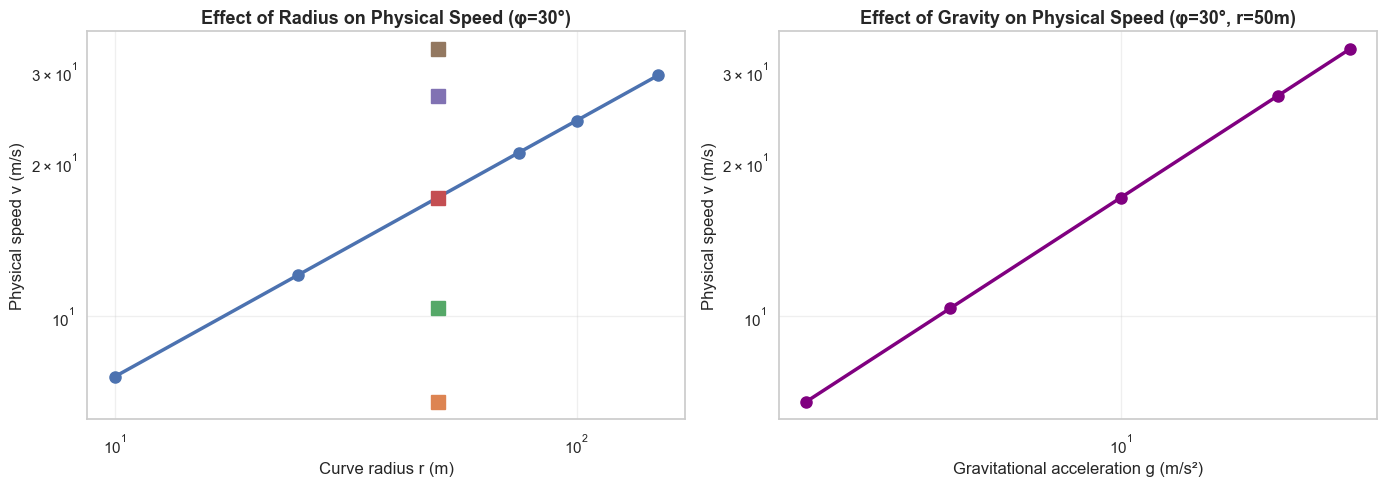

Sensitivity Analysis:

Physical speed formula: v = sqrt(tan(φ)) × sqrt(r×g)

This shows:
1. Dimensionless part depends ONLY on angle: sqrt(tan(φ))
2. Physical scaling: v ∝ sqrt(r), v ∝ sqrt(g)
3. If you double the radius: v increases by sqrt(2) ≈ 1.41×
4. If you double gravity: v increases by sqrt(2) ≈ 1.41×
5. Mass has NO effect!


In [5]:
phi_30 = np.radians(30)
v_star_30 = dimensionless_speed(phi_30)

radii = np.array([10, 25, 50, 75, 100, 150])
gravities = np.array([1.6, 3.7, 10, 25, 38])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for g_val in [10]:
    v_phys_r = [physical_speed(phi_30, r_val, g_val) for r_val in radii]
    ax.plot(radii, v_phys_r, 'o-', linewidth=2.5, markersize=8, label=f'g={g_val}m/s²')

for r_val in [50]:
    for g_val in gravities:
        v_phys_g = physical_speed(phi_30, r_val, g_val)
        ax.plot(r_val, v_phys_g, 's', markersize=10, label=f'r={r_val}m, g={g_val}m/s²')

ax.set_xlabel('Curve radius r (m)', fontsize=12)
ax.set_ylabel('Physical speed v (m/s)', fontsize=12)
ax.set_title(f'Effect of Radius on Physical Speed (φ=30°)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_xscale('log')
ax.set_yscale('log')

ax = axes[1]
v_phys_gravities = [physical_speed(phi_30, 50, g_val) for g_val in gravities]
ax.plot(gravities, v_phys_gravities, 'o-', linewidth=2.5, markersize=8, color='purple')
ax.set_xlabel('Gravitational acceleration g (m/s²)', fontsize=12)
ax.set_ylabel('Physical speed v (m/s)', fontsize=12)
ax.set_title(f'Effect of Gravity on Physical Speed (φ=30°, r=50m)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_xscale('log')
ax.set_yscale('log')

plt.tight_layout()
plt.show()

print('Sensitivity Analysis:')
print('\nPhysical speed formula: v = sqrt(tan(φ)) × sqrt(r×g)')
print('\nThis shows:')
print('1. Dimensionless part depends ONLY on angle: sqrt(tan(φ))')
print('2. Physical scaling: v ∝ sqrt(r), v ∝ sqrt(g)')
print('3. If you double the radius: v increases by sqrt(2) ≈ 1.41×')
print('4. If you double gravity: v increases by sqrt(2) ≈ 1.41×')
print('5. Mass has NO effect!')

## Summary: Key Takeaways

1. **Dimensionless speed** $v^* = \sqrt{\tan\phi}$ depends **only on banking angle**
2. **Physical speed** $v = \sqrt{\tan\phi} \times \sqrt{rg}$ scales with radius and gravity
3. **Mass is irrelevant** — a motorcycle and an 18-wheeler have the same safe speed
4. **Universal behavior** — all systems with the same angle are identical (dimensionlessly)
5. **Scaling laws**:
   - Double radius → speed increases by $\sqrt{2}$
   - Double gravity → speed increases by $\sqrt{2}$
   - Change angle → completely different dimensionless speed